# Explore the data!

This here notebook is just to play around with the data, load it, look at it, start plotting some graphs for curiosity's sake.

In [200]:
# imports
import numpy as np
import matplotlib as mpl
import pandas as pd
import pickle
from pathlib import Path


In [201]:
# Select the animal, headstage, and anatomical region explicitly.
data_dir = Path("C:/Users/cleme/Documents/etheremin/data")
animal = "NAPOLEON"
headstage = 0
region = "AC"

recording_regions = {
    ("FETA", 0): "AC", ("FETA", 1): "PMC",
    ("HERCULE", 0): "AC", ("HERCULE", 1): "PMC",
    ("MMELOIK", 0): "AC", ("MMELOIK", 1): "AC",
    ("NAPOLEON", 0): "AC", ("NAPOLEON", 1): "AC",
}
expected_region = recording_regions[(animal, headstage)]
if region != expected_region:
    raise ValueError(
        f"{animal} headstage {headstage} is {expected_region}, selected {region}."
    )

prefix = f"{animal}_hs_{headstage}_{region}_playback_0.005"
paths = [data_dir / f"{prefix}_{suffix}"
         for suffix in ("data_ss", "feature_ss", "neuron_idx_ss")]
for path in paths:
    if not path.is_file():
        raise FileNotFoundError(path)

with paths[0].open("rb") as f:
    neural_data = pickle.load(f)
with paths[1].open("rb") as f:
    features = pickle.load(f)
with paths[2].open("rb") as f:
    neuron_ids = pickle.load(f)

if not (len(neural_data) == len(features) == len(neuron_ids)):
    raise ValueError(f"Session counts do not match for {prefix}.")
for s in range(len(neural_data)):
    if neural_data[s].shape != (len(neuron_ids[s]), len(features[s])):
        raise ValueError(f"Neural data, features, and neuron IDs do not align in session {s}.")
print(f"Loaded {animal} headstage {headstage} ({region}), {len(neural_data)} sessions.")


Loaded NAPOLEON headstage 0 (AC), 13 sessions.


## Getting a hold of the data
See below: each animal has 3 files that describe the neural data, features, and neuron indexes. Each file is a list of 12 sessions (there's more originally, but i think the preprocessing step selects 12 for each in some way). So to look at one experiment, you need to look at the same element of each pkl file.

In [202]:
# Types and shapes
for name, obj in [
    ("neural_data", neural_data),
    ("features", features),
    ("neuron_ids", neuron_ids),
]:
    session = obj[0]
    print(f"{name}: {type(obj).__name__}, {len(obj)} sessions")
    print(f"  First session: {type(session).__name__}")
    print(f"  Shape: {session.shape}" if hasattr(session, "shape")
          else f"  Length: {len(session)}")

neural_data: list, 13 sessions
  First session: ndarray
  Shape: (33, 721235)
features: list, 13 sessions
  First session: DataFrame
  Shape: (721235, 17)
neuron_ids: list, 13 sessions
  First session: list
  Length: 33


In [203]:
# Choose a session and ranges (stop values excluded)
session = 0
unit_start, unit_stop = 0, 5
bin_start, bin_stop = 1000, 1010

print(f"Session {session} — neural data: units × time bins")
display(neural_data[session][unit_start:unit_stop, bin_start:bin_stop])

print("Features — same time bins:")
display(features[session].iloc[bin_start:bin_stop])

print("Neuron IDs — same units:")
display(neuron_ids[session][unit_start:unit_stop])

Session 0 — neural data: units × time bins


array([[0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 1., 0., 0., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 2.]])

Features — same time bins:


,Played_frequency,Condition,Block,Frequency_changes,Mock_frequency,Mock_change,Change_direction,Mock_direction,Speed_x,Speed_x_signed,Sound_speed,Position,Freq_position,Speed_bin,Acc_x_signed,Acc_x,Acc_sound
1000,715.0,0.0,0.0,False,0.0,False,0,0,2.045164,2.045164,2.045164,5.708762,5.708762,4.0,-0.199212,-0.199212,-0.199212
1001,715.0,0.0,0.0,False,0.0,False,0,0,1.844993,1.844993,1.844993,5.727212,5.727212,3.0,-0.200171,-0.200171,-0.200171
1002,715.0,0.0,0.0,False,0.0,False,0,0,1.646860,1.646860,1.646860,5.743681,5.743681,3.0,-0.198133,-0.198133,-0.198133
1003,715.0,0.0,0.0,False,0.0,False,0,0,1.454681,1.454681,1.454681,5.758227,5.758227,3.0,-0.192178,-0.192178,-0.192178
1004,715.0,0.0,0.0,False,0.0,False,0,0,1.271671,1.271671,1.271671,5.770944,5.770944,3.0,-0.183010,-0.183010,-0.183010
1005,715.0,0.0,0.0,False,0.0,False,0,0,1.101355,1.101355,1.101355,5.781958,5.781958,3.0,-0.170316,-0.170316,-0.170316
1006,715.0,0.0,0.0,False,0.0,False,0,0,0.942027,0.942027,0.942027,5.791378,5.791378,2.0,-0.159328,-0.159328,-0.159328
1007,715.0,0.0,0.0,False,0.0,False,0,0,0.799778,0.799778,0.799778,5.799376,5.799376,2.0,-0.142249,-0.142249,-0.142249
1008,715.0,0.0,0.0,False,0.0,False,0,0,0.671124,0.671124,0.671124,5.806087,5.806087,2.0,-0.128654,-0.128654,-0.128654
1009,715.0,0.0,0.0,False,0.0,False,0,0,0.557568,0.557568,0.557568,5.811663,5.811663,2.0,-0.113556,-0.113556,-0.113556


Neuron IDs — same units:


['NAPOLEON_20241202_SESSION_03_headstage_0_neuron0',
 'NAPOLEON_20241202_SESSION_03_headstage_0_neuron1',
 'NAPOLEON_20241202_SESSION_03_headstage_0_neuron2',
 'NAPOLEON_20241202_SESSION_03_headstage_0_neuron3',
 'NAPOLEON_20241202_SESSION_03_headstage_0_neuron4']

## Plotting features

Now lets look at the features to understand the important ones, what they look like etc.

In [204]:
# imports
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d

# seaborn settings
sns.set_theme(
    style="ticks",
    context="notebook",
    palette="colorblind",
    rc={
        "figure.figsize": (10, 4),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
    },
)

# Select session and define dt
session = 0
dt = 0.005

### Plotting a unit's FR with gaussian smoothing

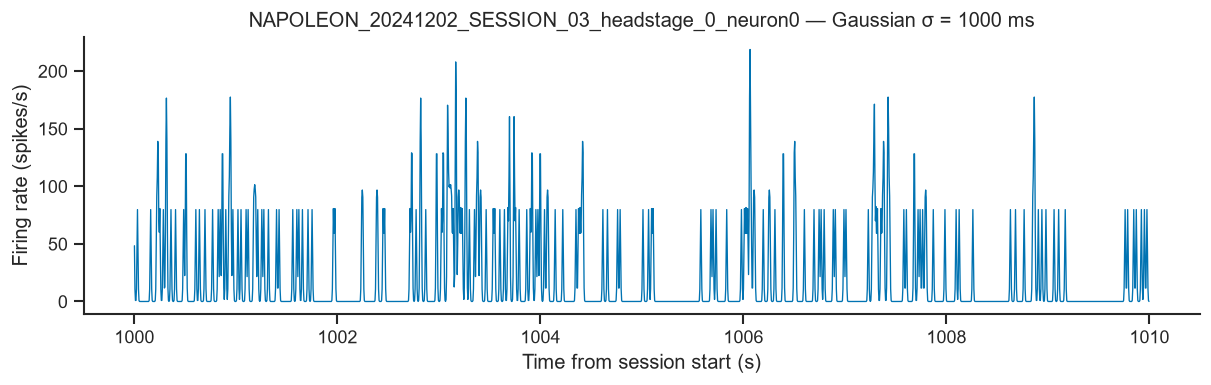

In [205]:
# Choose neuron, time window, and smoothing
unit = 0
start_s = 1000
stop_s = 1010
dt = 0.005
# sigma is gaussian smoothing value, expressed in bins
sigma = 1

counts = neural_data[session][unit]

start_bin = int(start_s / dt)
stop_bin = len(counts) if stop_s is None else min(int(stop_s / dt), len(counts))

# Convert counts to spikes/s and smooth the full recording
smooth_rate = gaussian_filter1d(
    counts.astype(float) / dt,
    sigma
)

activity = smooth_rate[start_bin:stop_bin]
time_s = (start_bin + np.arange(len(activity))) * dt

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(time_s, activity, linewidth=0.8)
ax.set(
    xlabel="Time from session start (s)",
    ylabel="Firing rate (spikes/s)",
    title=f"{neuron_ids[session][unit]} — Gaussian σ = {sigma * 1000:g} ms",
)
plt.show()

### Plotting the session's different features

Here, we will look specifically at the following:
Played_frequency
Condition
Frequency_changes
Mock_frequency
Mock_change
Position

There's others, but i need to check if they are real or reliquates

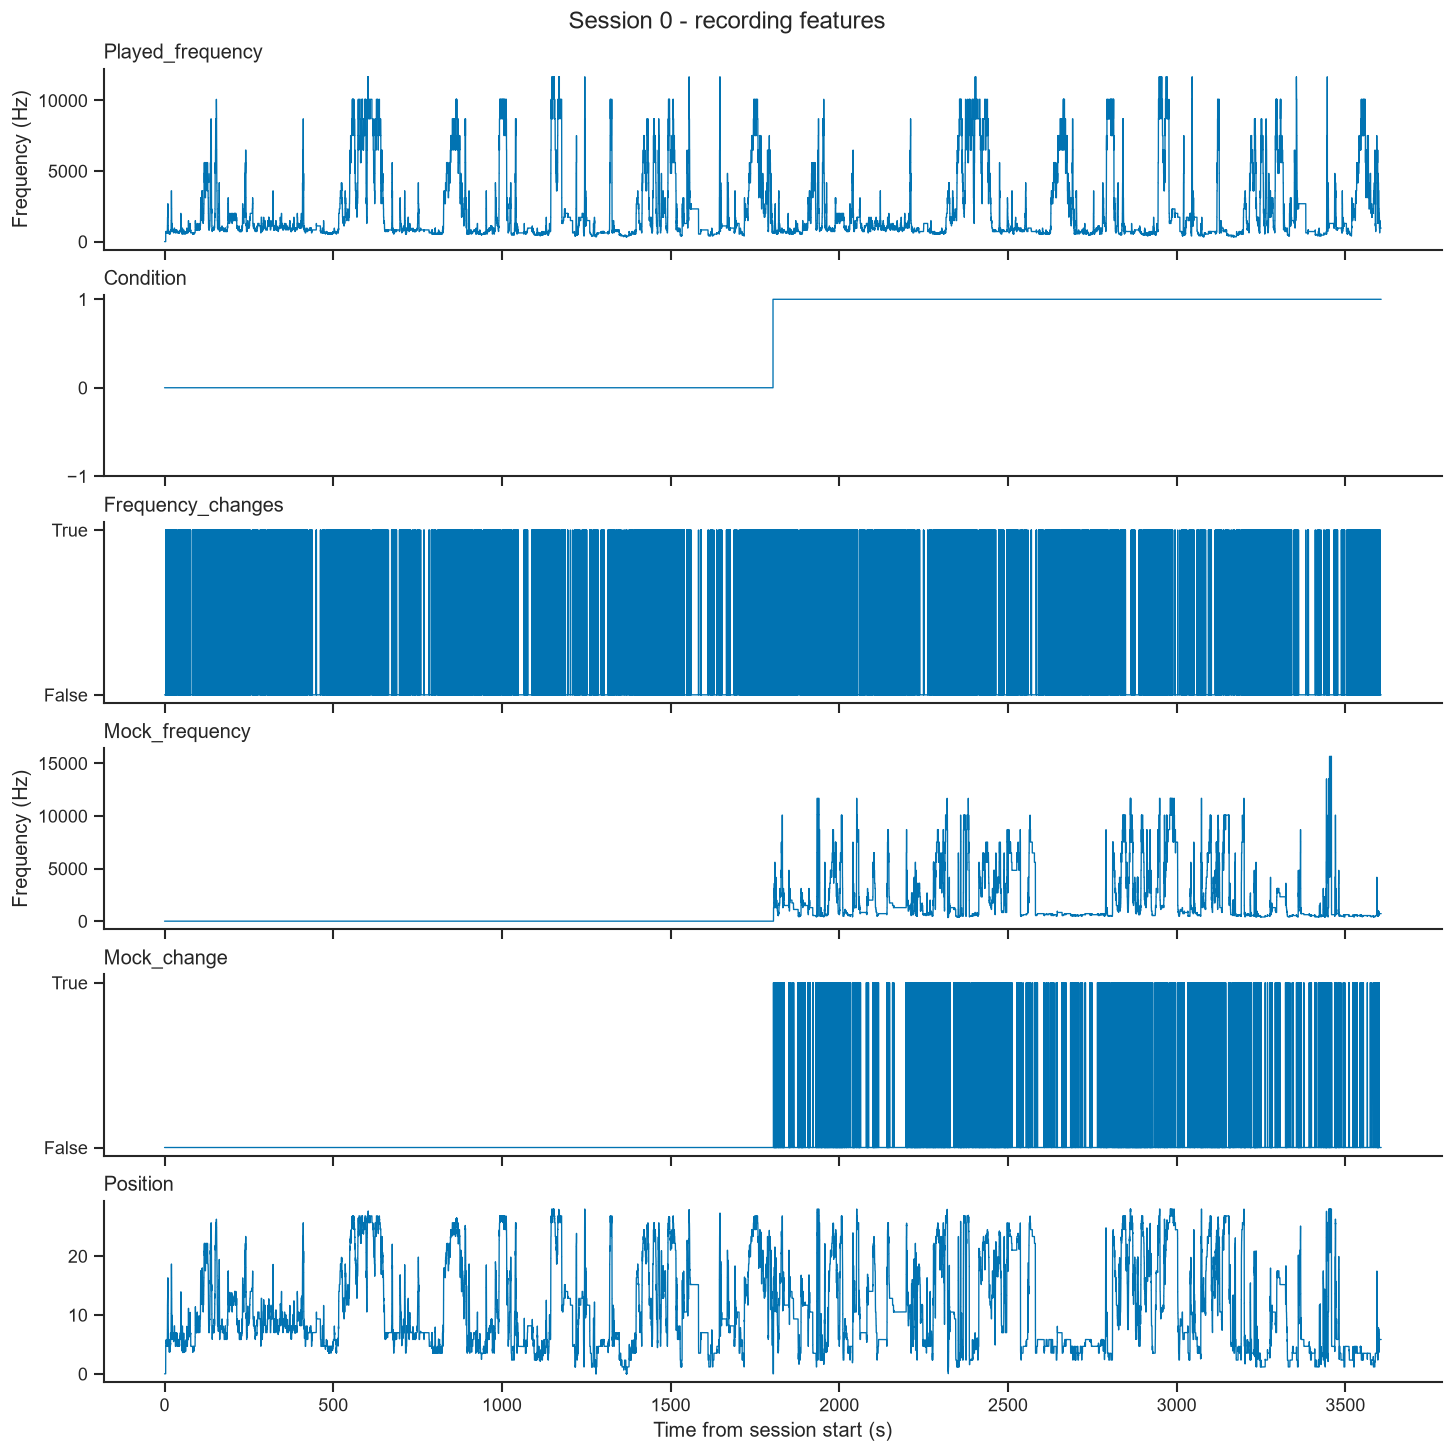

In [206]:
import numpy as np
import matplotlib.pyplot as plt


start_s = 0
stop_s = None  # use None for the full session

features_to_plot = [
    "Played_frequency",
    "Condition",
    "Frequency_changes",
    "Mock_frequency",
    "Mock_change",
    "Position",
]

# Convert the selected time window to bin indices
start_bin = int(start_s / dt)
stop_bin = (
    len(features[session])
    if stop_s is None
    else min(int(stop_s / dt), len(features[session]))
)
time_s = np.arange(start_bin, stop_bin) * dt

# One panel per feature, all sharing the same time axis
fig, axes = plt.subplots(
    len(features_to_plot), 1,
    figsize=(12, 2 * len(features_to_plot)), sharex=True, layout="constrained",
)

for ax, feature in zip(axes, features_to_plot):
    ax.step(
        time_s,
        features[session][feature].iloc[start_bin:stop_bin],
        where="post",
        linewidth=0.8,
    )
    ax.set_title(feature, loc="left")
    if feature in ("Played_frequency", "Mock_frequency"):
        ax.set_ylabel("Frequency (Hz)")
    elif feature in ("Frequency_changes", "Mock_change"):
        ax.set_yticks([0, 1], labels=["False", "True"])
    elif feature == "Condition":
        ax.set_yticks([-1, 0, 1])

axes[-1].set_xlabel("Time from session start (s)")
fig.suptitle(f"Session {session} - recording features")
plt.show()


## Single-neuron responses aligned to frequency changes

Each row of `event_responses` contains one selected neuron's Gaussian-smoothed spike counts around one frequency-change event. `raw_event_responses` retains the unsmoothed counts for comparison. Columns are 5 ms bins relative to the event: **-0.300 s up to, but excluding, +0.050 s** (70 bins). The event bin is at time zero.

We use every bin marked `Frequency_changes == True`, across all conditions. Consecutive True bins are separate events. Windows can overlap; events near either session boundary are excluded if their full window is unavailable. The full-session trace is smoothed before extracting windows, without baseline subtraction. `sigma_bins` is the Gaussian standard deviation in bins (default: 1 bin = 5 ms). The mean plot converts smoothed counts per bin to spikes/s. Gaussian smoothing is symmetric: activity after an event can spread into the pre-event period, so it should not be used to infer precise response onset times.

Responses are split by `Condition` **at the event bin**: tracking (`0`) and playback (`1`). Other conditions (including `-1`) remain in the full matrix but are excluded from this comparison. A window may cross a condition boundary; it keeps the label at time zero.

Set `sigma_bins = None` to use unfiltered counts and firing rates. Positive values apply Gaussian smoothing, with sigma expressed in bins.


In [207]:
# Select one neuron and the event window
import numpy as np
from scipy.ndimage import gaussian_filter1d

session = 11
unit = 0
dt = 0.005
before_s = 0.3
after_s = 0.3
sigma_bins = None  # None skips filtering; a positive number sets Gaussian sigma in bins

before_bins = int(round(before_s / dt))
after_bins = int(round(after_s / dt))
relative_bins = np.arange(-before_bins, after_bins)
event_time_s = relative_bins * dt

neuron_counts = np.asarray(neural_data[session][unit])
if len(neuron_counts) != len(features[session]):
    raise ValueError("Neural data and features must have the same number of time bins.")

# Optionally smooth along time before extracting event windows.
if sigma_bins is None:
    smoothed_counts = neuron_counts.astype(float)
    smoothing_label = "No filtering"
else:
    if not np.isfinite(sigma_bins) or sigma_bins <= 0:
        raise ValueError("sigma_bins must be None or a positive finite number.")
    smoothed_counts = gaussian_filter1d(
        neuron_counts.astype(float), sigma=sigma_bins, mode="reflect",
    )
    smoothing_label = f"Gaussian sigma = {sigma_bins * dt * 1000:g} ms"
print(smoothing_label)


No filtering


In [208]:
# Find events and retain only those with a complete window
all_event_bins = np.flatnonzero(
    features[session]["Frequency_changes"].fillna(False).eq(True).to_numpy()
)
complete_window = (
    (all_event_bins >= before_bins)
    & (all_event_bins + after_bins <= len(neuron_counts))
)
event_bins = all_event_bins[complete_window]

# Rows = events; columns = time bins relative to each event
# Empty selections retain the shape (0, number of time bins).
raw_event_responses = neuron_counts[event_bins[:, None] + relative_bins[None, :]]
event_responses = smoothed_counts[event_bins[:, None] + relative_bins[None, :]]

print("Neuron:", neuron_ids[session][unit])
print("Frequency-change events:", len(all_event_bins))
print("Skipped at session boundaries:", np.count_nonzero(~complete_window))
print("Response matrix (events, time bins):", event_responses.shape)
print("Event bin column:", before_bins)

# The row order matches event_bins; these are times from session start.
event_times_s = event_bins * dt


Neuron: NAPOLEON_20250109_SESSION_00_headstage_0_neuron0
Frequency-change events: 11349
Skipped at session boundaries: 0
Response matrix (events, time bins): (11349, 120)
Event bin column: 60


In [209]:
# Split rows using the condition at each retained frequency-change event
# iloc selects by bin position, in exactly the same order as event_responses.
event_conditions = features[session]["Condition"].iloc[event_bins]
tracking_mask = event_conditions.eq(0).fillna(False).to_numpy(dtype=bool)
playback_mask = event_conditions.eq(1).fillna(False).to_numpy(dtype=bool)

tracking_responses = event_responses[tracking_mask]
playback_responses = event_responses[playback_mask]
tracking_event_times_s = event_times_s[tracking_mask]
playback_event_times_s = event_times_s[playback_mask]

print("Tracking matrix (events, time bins):", tracking_responses.shape)
print("Playback matrix (events, time bins):", playback_responses.shape)
print("Other/unknown condition events:", np.count_nonzero(~(tracking_mask | playback_mask)))


Tracking matrix (events, time bins): (5678, 120)
Playback matrix (events, time bins): (5671, 120)
Other/unknown condition events: 0


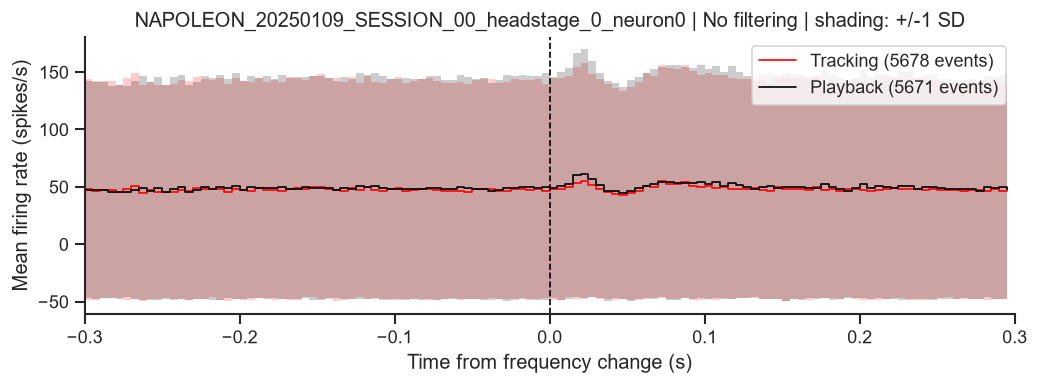

In [210]:
# Compare mean Gaussian-smoothed responses, converting counts/bin to spikes/s
import matplotlib.pyplot as plt

# None indicates a condition with no retained events.
tracking_mean_hz = tracking_responses.mean(axis=0) / dt if len(tracking_responses) else None
playback_mean_hz = playback_responses.mean(axis=0) / dt if len(playback_responses) else None

# Shading shows mean +/- 1 sample SD across events.
fig, ax = plt.subplots(figsize=(10, 3))
for label, responses, mean_hz, color in [
    ("Tracking", tracking_responses, tracking_mean_hz, "red"),
    ("Playback", playback_responses, playback_mean_hz, "black"),
]:
    if mean_hz is None:
        print(f"{label}: no events with a complete window.")
        continue
    line, = ax.step(event_time_s, mean_hz, where="post", linewidth=1, color=color,
                    label=f"{label} ({len(responses)} events)")
    # Sample SD across events at each time bin, in spikes/s.
    if len(responses) > 1:
        sd_hz = responses.std(axis=0, ddof=1) / dt
        ax.fill_between(
            event_time_s, mean_hz - sd_hz, mean_hz + sd_hz,
            step="post", color=line.get_color(), alpha=0.2, linewidth=0,
        )

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set(
    xlabel="Time from frequency change (s)",
    ylabel="Mean firing rate (spikes/s)",
    title=f"{neuron_ids[session][unit]} | {smoothing_label} | shading: +/-1 SD",
    xlim=(-before_bins * dt, after_bins * dt),
)
if tracking_mean_hz is not None or playback_mean_hz is not None:
    ax.legend()
plt.show()


## Responses grouped by the new played frequency

Run the event-extraction cells above first. This section reuses their selected neuron, time window, and Gaussian smoothing. Each event is grouped by `Played_frequency` **at its event bin** (the new played frequency). Each panel compares tracking and playback at one destination frequency, with shared axes and event counts in the legends. Other conditions and missing/nonfinite frequencies are excluded from this comparison.

`responses_by_frequency[frequency]["tracking"]` and `["playback"]` retain the event-by-time matrices in smoothed counts/bin. The plots show their means in spikes/s. Groups can have different numbers of events; a small group will give a less stable average. These are averages across transitions arriving at a frequency, not isolated-tone responses: preceding frequencies and nearby changes can also differ.

Shading shows the mean plus or minus one sample standard deviation across events at each time bin. It describes event-to-event variability. A group containing one event is drawn with a line only.


In [211]:
# Label every extracted event with its new played frequency
import numpy as np
import pandas as pd

event_frequencies = features[session]["Played_frequency"].iloc[event_bins].to_numpy(dtype=float)
frequency_valid = np.isfinite(event_frequencies)
comparison_mask = frequency_valid & (tracking_mask | playback_mask)
new_frequencies = np.unique(event_frequencies[comparison_mask])

# Keep a separate event-response matrix for each frequency and condition
responses_by_frequency = {}
frequency_counts = []
for frequency in new_frequencies:
    frequency_mask = frequency_valid & (event_frequencies == frequency)
    responses_by_frequency[frequency] = {
        "tracking": event_responses[frequency_mask & tracking_mask],
        "playback": event_responses[frequency_mask & playback_mask],
    }
    frequency_counts.append({
        "New played frequency (Hz)": frequency,
        "Tracking events": len(responses_by_frequency[frequency]["tracking"]),
        "Playback events": len(responses_by_frequency[frequency]["playback"]),
    })

print("Destination frequencies:", len(new_frequencies))
print("Tracking/playback events with missing or nonfinite frequency:",
      np.count_nonzero((tracking_mask | playback_mask) & ~frequency_valid))
display(pd.DataFrame(frequency_counts, columns=[
    "New played frequency (Hz)", "Tracking events", "Playback events",
]))


Destination frequencies: 24
Tracking/playback events with missing or nonfinite frequency: 0


,New played frequency (Hz),Tracking events,Playback events
0,397.0,59,59
1,460.0,150,150
2,533.0,222,222
3,617.0,637,637
4,715.0,624,624
5,828.0,280,280
6,959.0,280,280
7,1111.0,234,234
8,1287.0,204,204
9,1490.0,164,164


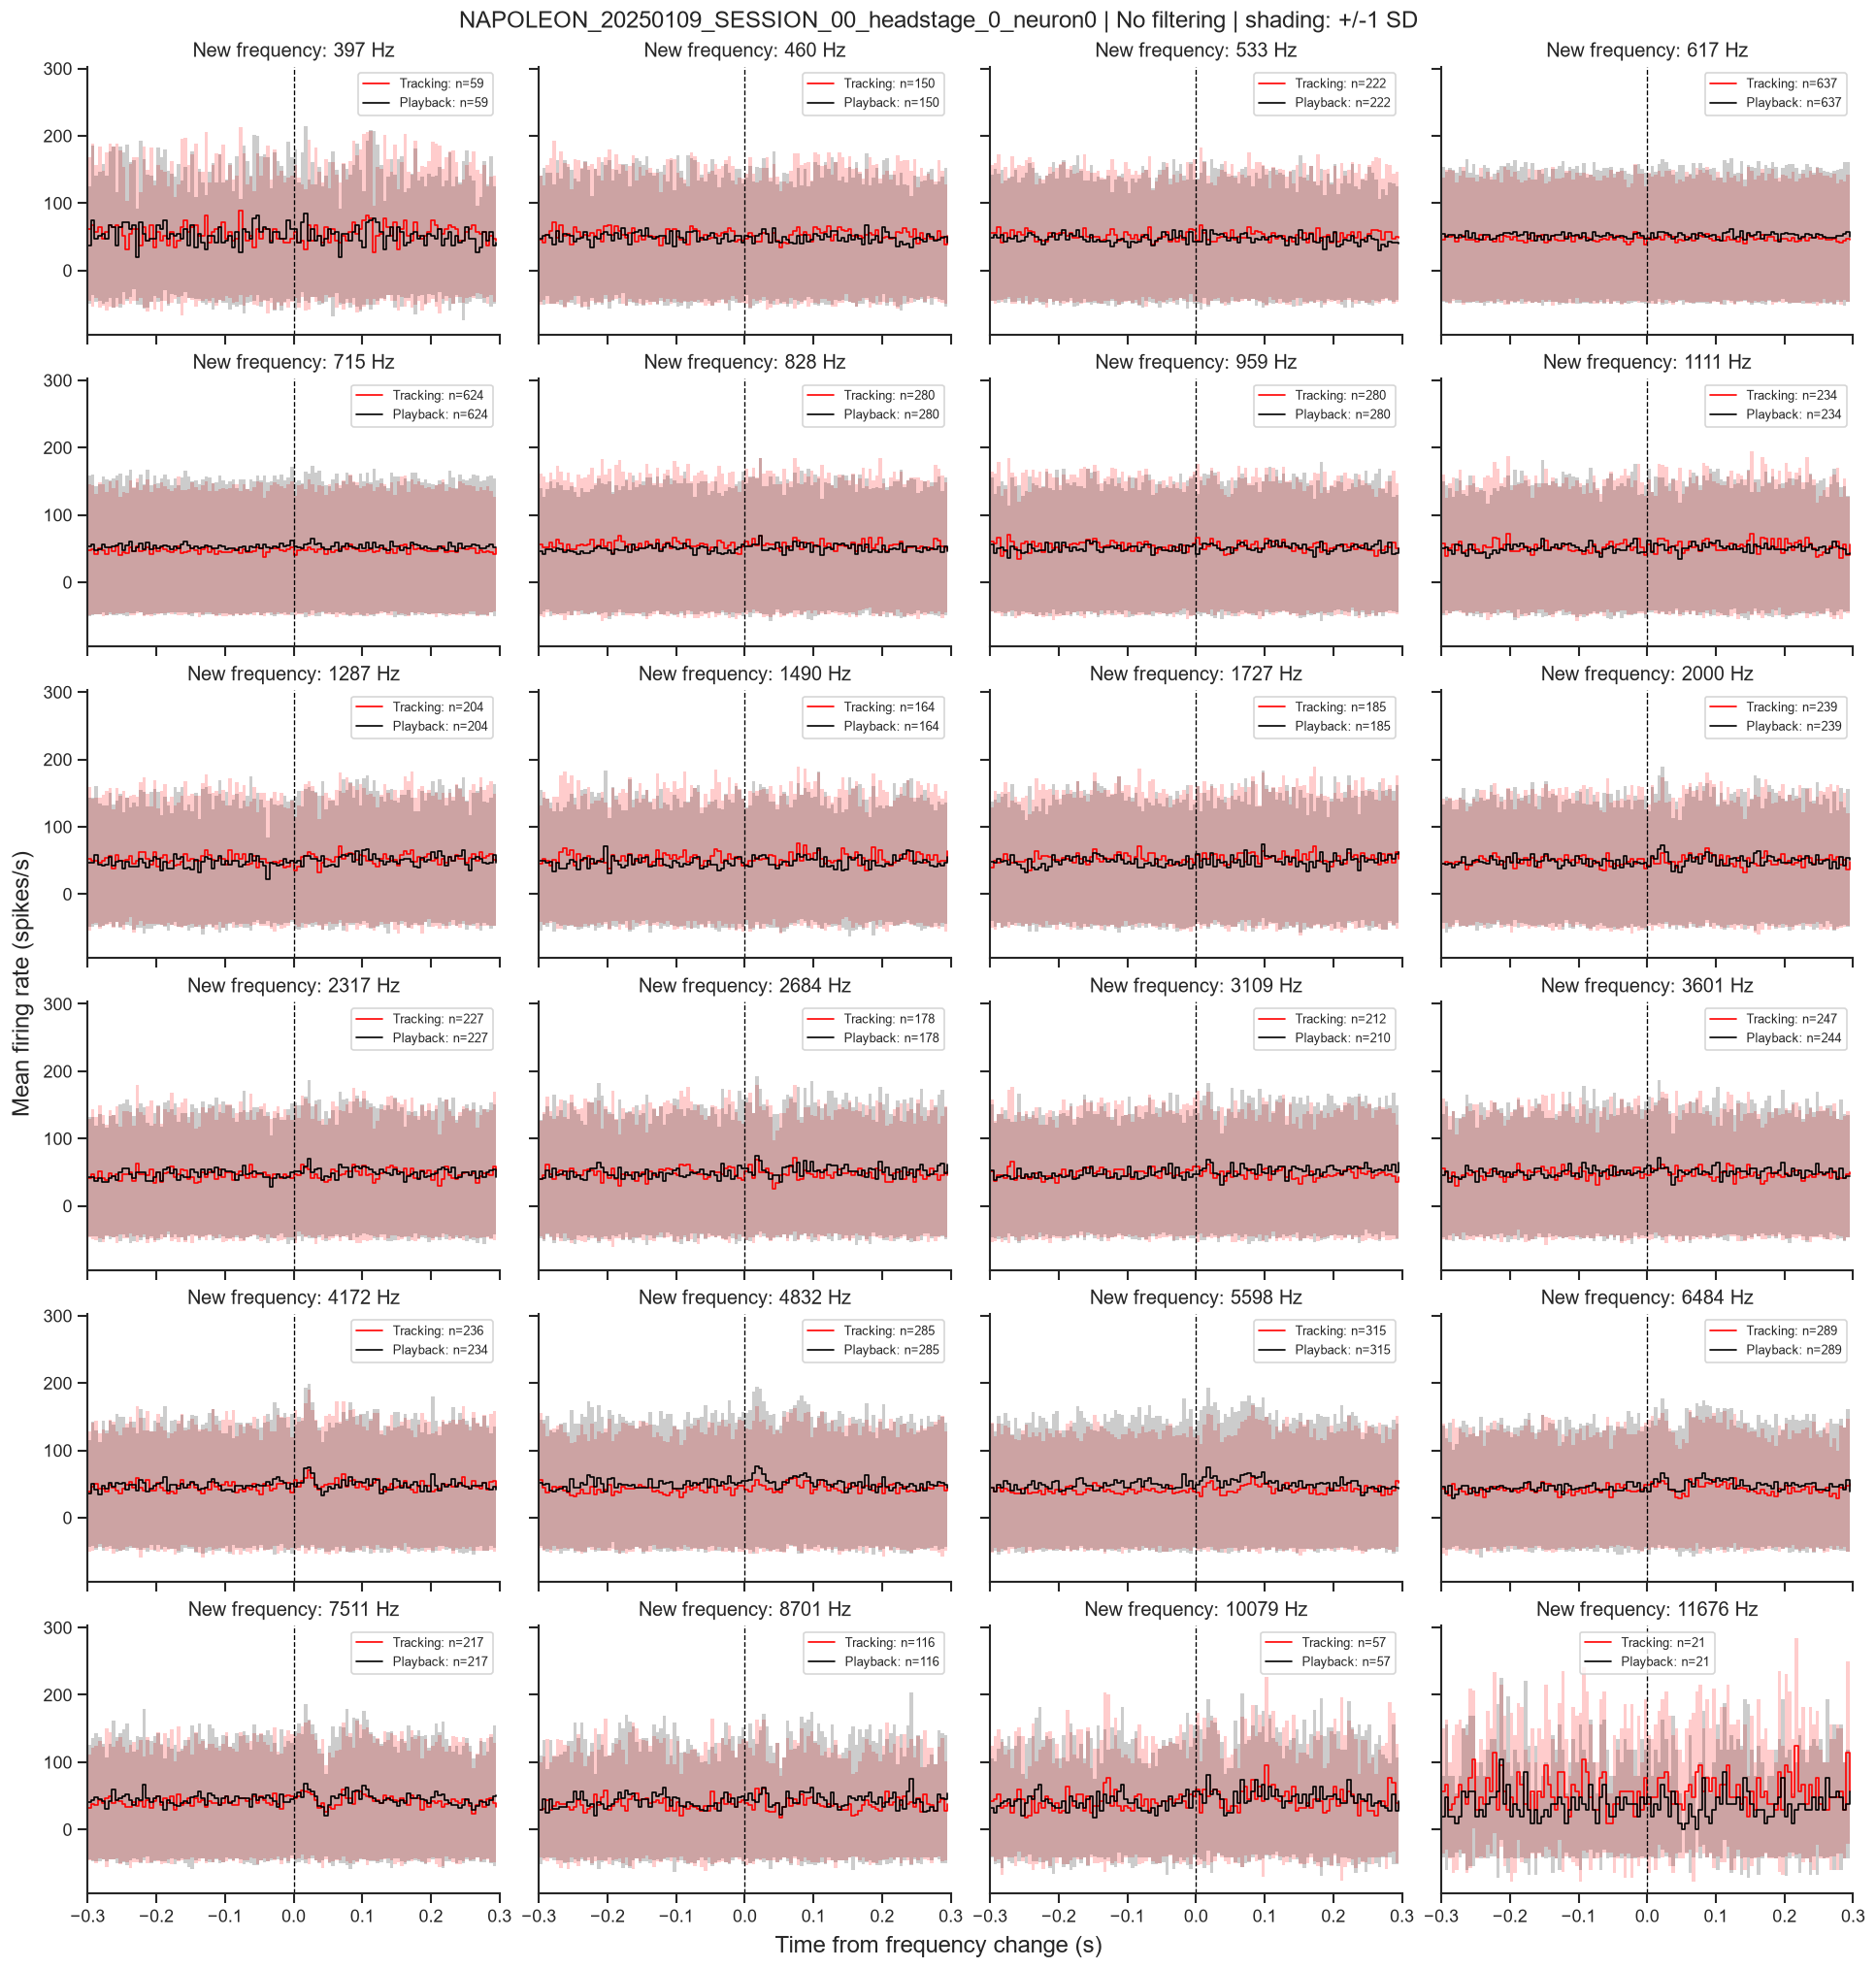

In [212]:
# Plot all destination frequencies, keeping the same scales for comparison
import matplotlib.pyplot as plt

if len(new_frequencies) == 0:
    raise ValueError("No tracking/playback events with a valid played frequency.")

ncols = min(4, len(new_frequencies))
nrows = int(np.ceil(len(new_frequencies) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(4 * ncols, 2.8 * nrows),
    sharex=True, sharey=True, squeeze=False, layout="constrained",
)

for ax, frequency in zip(axes.flat, new_frequencies):
    for condition, label, color in [
        ("tracking", "Tracking", "red"),
        ("playback", "Playback", "black"),
    ]:
        responses = responses_by_frequency[frequency][condition]
        if len(responses) == 0:
            continue
        mean_hz = responses.mean(axis=0) / dt
        ax.step(
            event_time_s, mean_hz,
            where="post", linewidth=1, color=color,
            label=f"{label}: n={len(responses)}",
        )
        # Sample SD across events at each time bin, in spikes/s.
        if len(responses) > 1:
            sd_hz = responses.std(axis=0, ddof=1) / dt
            ax.fill_between(
                event_time_s, mean_hz - sd_hz, mean_hz + sd_hz,
                step="post", color=color, alpha=0.2, linewidth=0,
            )
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f"New frequency: {frequency:g} Hz")
    ax.set_xlim(-before_bins * dt, after_bins * dt)
    ax.legend(fontsize=8)

for ax in list(axes.flat)[len(new_frequencies):]:
    ax.set_visible(False)

fig.supxlabel("Time from frequency change (s)")
fig.supylabel("Mean firing rate (spikes/s)")
fig.suptitle(
    f"{neuron_ids[session][unit]} | {smoothing_label} | shading: +/-1 SD"
)
plt.show()


## Individual event responses at one selected frequency

Use the frequency slider to select an available destination frequency in Hz. Choose tracking or playback, then use the event slider to display one Gaussian-smoothed response. Event numbers start at 1 within the chosen frequency and condition, in session order. Changing frequency or condition resets the event slider to 1. An empty selection displays a message and disables the event slider.

This uses the neuron and smoothing selected in the event-extraction section. Rerun event extraction and frequency grouping after changing the neuron. The vertical scale is fixed across all frequencies, conditions, and events for comparison. Plots update when a slider is released.


In [213]:
# Browse individual events by destination frequency and condition
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

if len(new_frequencies) == 0:
    raise ValueError("No destination frequencies are available. Run frequency grouping first.")

frequency_slider = widgets.SelectionSlider(
    options=[(f"{frequency:g} Hz", frequency) for frequency in new_frequencies],
    description="Frequency", continuous_update=False,
    layout=widgets.Layout(width="600px"),
    style={"description_width": "initial"},
)
condition_selector = widgets.Dropdown(
    options=[("Tracking", "tracking"), ("Playback", "playback")],
    description="Condition",
)
event_slider = widgets.IntSlider(
    value=1, min=1, max=1, step=1, description="Event",
    continuous_update=False, layout=widgets.Layout(width="600px"),
)
event_plot_output = widgets.Output()

# Keep the same vertical scale across frequencies, conditions, and events.
maximum_rate_hz = max(
    responses.max() / dt
    for groups in responses_by_frequency.values()
    for responses in groups.values()
    if len(responses) > 0
)
plot_upper_hz = max(1.0, maximum_rate_hz * 1.05)


def draw_selected_event(change=None):
    frequency = frequency_slider.value
    condition = condition_selector.value
    responses = responses_by_frequency[frequency][condition]
    color = "red" if condition == "tracking" else "black"

    with event_plot_output:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 3), layout="constrained")
        if len(responses) == 0:
            ax.text(0.5, 0.5, "No events for this frequency and condition",
                    transform=ax.transAxes, ha="center", va="center")
            event_label = "0 events"
        else:
            ax.step(
                event_time_s, responses[event_slider.value - 1] / dt,
                where="post", color=color, linewidth=1.2,
            )
            event_label = f"event {event_slider.value}/{len(responses)}"
        ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set(
            xlabel="Time from frequency change (s)",
            ylabel="Firing rate (spikes/s)",
            title=(f"{neuron_ids[session][unit]} | {frequency:g} Hz"
                   f" | {condition.capitalize()} | {event_label}"),
            xlim=(-before_bins * dt, after_bins * dt),
            ylim=(0, plot_upper_hz),
        )
        display(fig)
        plt.close(fig)


def change_event_selection(change=None):
    # Reset the event index when frequency or condition changes.
    responses = responses_by_frequency[frequency_slider.value][condition_selector.value]
    event_slider.unobserve(draw_selected_event, names="value")
    event_slider.value = 1
    event_slider.max = max(1, len(responses))
    event_slider.disabled = len(responses) == 0
    event_slider.observe(draw_selected_event, names="value")
    draw_selected_event()


frequency_slider.observe(change_event_selection, names="value")
condition_selector.observe(change_event_selection, names="value")
event_slider.observe(draw_selected_event, names="value")
display(widgets.VBox([
    frequency_slider, condition_selector, event_slider, event_plot_output,
]))
change_event_selection()


## Population-averaged responses across all frequencies

For each unit and each event, subtract that unit's mean Gaussian-smoothed firing rate over **[-0.3, 0) seconds**. Average the corrected responses across all units in the selected session with equal weight per unit, then average all frequency-change events within tracking or playback. Each event contributes equally, so frequencies with more events contribute more to the pooled mean.

The plot shows tracking in red and playback in black, expressed as change from baseline in spikes/s per unit. Run event extraction with `before_s >= 0.3` and condition splitting before this cell.

Set `sigma_bins = None` to use unfiltered counts and firing rates. Positive values apply Gaussian smoothing, with sigma expressed in bins.


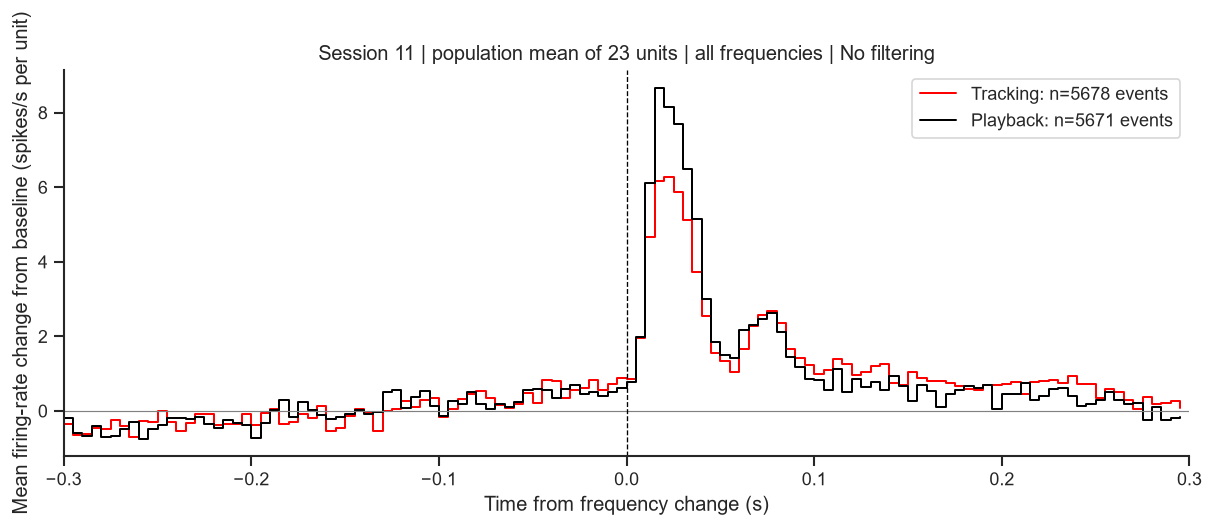

In [214]:
# Population mean across all frequency-change events in the selected session
# Run event extraction and condition splitting above first.
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

population_counts = np.asarray(neural_data[session])
if population_counts.shape[0] == 0:
    raise ValueError("The selected session contains no units.")
if population_counts.shape[1] != len(features[session]):
    raise ValueError("Neural data and features must have the same number of time bins.")
if len(event_bins) == 0:
    raise ValueError("No frequency-change events have a complete window.")

# Subtract each unit's own pre-event mean for each event before averaging units.
baseline_duration_s = 0.3
baseline_bins = int(round(baseline_duration_s / dt))
if baseline_bins < 1 or before_bins < baseline_bins:
    raise ValueError("Set before_s to at least 0.3 s and rerun event extraction first.")
baseline_mask = (relative_bins >= -baseline_bins) & (relative_bins < 0)
population_event_responses_hz = np.zeros(
    (len(event_bins), len(relative_bins)), dtype=float,
)

if sigma_bins is None:
    smoothing_label = "No filtering"
else:
    if not np.isfinite(sigma_bins) or sigma_bins <= 0:
        raise ValueError("sigma_bins must be None or a positive finite number.")
    smoothing_label = f"Gaussian sigma = {sigma_bins * dt * 1000:g} ms"

for unit_counts in population_counts:
    unit_smoothed_hz = unit_counts.astype(float) / dt
    if sigma_bins is not None:
        unit_smoothed_hz = gaussian_filter1d(
            unit_smoothed_hz, sigma=sigma_bins, mode="reflect",
        )
    unit_event_responses_hz = unit_smoothed_hz[
        event_bins[:, None] + relative_bins[None, :]
    ]
    # One baseline value for each event, computed from [-0.3, 0) seconds.
    unit_event_baselines_hz = unit_event_responses_hz[:, baseline_mask].mean(
        axis=1, keepdims=True,
    )
    population_event_responses_hz += (
        unit_event_responses_hz - unit_event_baselines_hz
    )

# Equal weight per unit, followed below by equal weight per event within each group.
population_event_responses_hz /= population_counts.shape[0]

# Pool all destination frequencies, weighting each event equally within condition.
population_means_hz = {}
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")

for condition, label, condition_mask, color in [
    ("tracking", "Tracking", tracking_mask, "red"),
    ("playback", "Playback", playback_mask, "black"),
]:
    condition_responses = population_event_responses_hz[condition_mask]
    if len(condition_responses) == 0:
        print(f"{label}: no events with a complete window.")
        continue
    population_mean_hz = condition_responses.mean(axis=0)
    population_means_hz[condition] = population_mean_hz
    ax.step(
        event_time_s, population_mean_hz, where="post",
        color=color, linewidth=1.2,
        label=f"{label}: n={len(condition_responses)} events",
    )

ax.axhline(0, color="gray", linewidth=0.7)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set(
    xlabel="Time from frequency change (s)",
    ylabel="Mean firing-rate change from baseline (spikes/s per unit)",
    title=(f"Session {session} | population mean of {population_counts.shape[0]} units"
           f" | all frequencies | {smoothing_label}"),
    xlim=(-before_bins * dt, after_bins * dt),
)
if population_means_hz:
    ax.legend()
plt.show()
